In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/cardio_train.csv", sep=";")

df.describe()



,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,49972.419900,19468.865814,1.349571,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700
std,28851.302323,2467.251667,0.476838,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003
min,0.000000,10798.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,25006.750000,17664.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,50001.500000,19703.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,74889.250000,21327.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,99999.000000,23713.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


In [2]:
df[(df["ap_hi"] <= 0) | (df["ap_lo"] <= 0)][["ap_hi", "ap_lo"]].head(20)


,ap_hi,ap_lo
2014,906,0
4607,-100,80
13489,130,0
16021,-115,70
16459,138,0
17381,138,0
20536,-100,70
22923,149,0
23867,906,0
23988,-140,90


In [3]:
df[(df["ap_hi"] <= 0) | (df["ap_lo"] <= 0)][["ap_hi", "ap_lo"]].head(20)

,ap_hi,ap_lo
2014,906,0
4607,-100,80
13489,130,0
16021,-115,70
16459,138,0
17381,138,0
20536,-100,70
22923,149,0
23867,906,0
23988,-140,90


In [4]:
invalid_bp = df[(df["ap_hi"] <= 0) | (df["ap_lo"] <= 0)]

invalid_bp.shape

(29, 13)

In [5]:
df[df["ap_hi"] > 200][["ap_hi", "ap_lo"]].head(20)

,ap_hi,ap_lo
1328,220,120
1876,902,60
2014,906,0
2142,210,1100
2278,220,110
4817,909,60
4981,220,160
7763,11500,90
8915,1420,80
8919,210,110


In [6]:
df[df["ap_lo"] > 130][["ap_hi", "ap_lo"]].head(20)

,ap_hi,ap_lo
228,160,1100
241,160,1000
260,140,800
329,160,1000
345,140,1000
473,150,1033
474,120,150
559,200,1000
613,140,1000
649,190,1100


In [7]:
df[df["ap_lo"] >= df["ap_hi"]][["ap_hi", "ap_lo"]].head(20)

,ap_hi,ap_lo
228,160,1100
241,160,1000
260,140,800
329,160,1000
345,140,1000
473,150,1033
474,120,150
559,200,1000
567,14,90
613,140,1000


In [8]:
df[["weight"]].describe()


,weight
count,70000.000000
mean,74.205690
std,14.395757
min,10.000000
25%,65.000000
50%,72.000000
75%,82.000000
max,200.000000


In [9]:
df["gender"].value_counts()

gender
1    45530
2    24470
Name: count, dtype: int64

In [10]:
df["cholesterol"].value_counts().sort_index()

cholesterol
1    52385
2     9549
3     8066
Name: count, dtype: int64

In [11]:
df["gluc"].value_counts().sort_index()

gluc
1    59479
2     5190
3     5331
Name: count, dtype: int64

In [12]:
print("Smoking:")
print(df["smoke"].value_counts())

print("\nAlcohol:")
print(df["alco"].value_counts())

print("\nPhysical Activity:")
print(df["active"].value_counts())

Smoking:
smoke
0    63831
1     6169
Name: count, dtype: int64

Alcohol:
alco
0    66236
1     3764
Name: count, dtype: int64

Physical Activity:
active
1    56261
0    13739
Name: count, dtype: int64


In [13]:
df["cardio"].value_counts()

cardio
0    35021
1    34979
Name: count, dtype: int64

In [14]:
df["cardio"].value_counts(normalize=True) * 100

cardio
0    50.03
1    49.97
Name: proportion, dtype: float64

In [15]:
df.corr(numeric_only=True)


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
id,1.000000,0.003457,0.003502,-0.003038,-0.001830,0.003356,-0.002529,0.006106,0.002467,-0.003699,0.001210,0.003755,0.003799
age,0.003457,1.000000,-0.022811,-0.081515,0.053684,0.020764,0.017647,0.154424,0.098703,-0.047633,-0.029723,-0.009927,0.238159
gender,0.003502,-0.022811,1.000000,0.499033,0.155406,0.006005,0.015254,-0.035821,-0.020491,0.338135,0.170966,0.005866,0.008109
height,-0.003038,-0.081515,0.499033,1.000000,0.290968,0.005488,0.006150,-0.050226,-0.018595,0.187989,0.094419,-0.006570,-0.010821
weight,-0.001830,0.053684,0.155406,0.290968,1.000000,0.030702,0.043710,0.141768,0.106857,0.067780,0.067113,-0.016867,0.181660
ap_hi,0.003356,0.020764,0.006005,0.005488,0.030702,1.000000,0.016086,0.023778,0.011841,-0.000922,0.001408,-0.000033,0.054475
ap_lo,-0.002529,0.017647,0.015254,0.006150,0.043710,0.016086,1.000000,0.024019,0.010806,0.005186,0.010601,0.004780,0.065719
cholesterol,0.006106,0.154424,-0.035821,-0.050226,0.141768,0.023778,0.024019,1.000000,0.451578,0.010354,0.035760,0.009911,0.221147
gluc,0.002467,0.098703,-0.020491,-0.018595,0.106857,0.011841,0.010806,0.451578,1.000000,-0.004756,0.011246,-0.006770,0.089307
smoke,-0.003699,-0.047633,0.338135,0.187989,0.067780,-0.000922,0.005186,0.010354,-0.004756,1.000000,0.340094,0.025858,-0.015486


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df["age_years"], bins=30)
plt.xlabel("Age (years)")
plt.ylabel("Number of Patients")
plt.title("Age Distribution")
plt.show()

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(df["weight"], bins=30)
plt.xlabel("Weight (kg)")
plt.ylabel("Number of Patients")
plt.title("Weight Distribution")
plt.show()

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(df["ap_hi"], bins=50)
plt.xlabel("Systolic Blood Pressure")
plt.ylabel("Number of Patients")
plt.title("Systolic Blood Pressure Distribution")
plt.show()

In [ ]:
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Invalid BP rows:", len(invalid_bp))
print("Target distribution:")
print(df["cardio"].value_counts())

In [ ]:
df["cardio"].value_counts(normalize=True) * 100

In [ ]:
df["age_years"] = df["age"] / 365.25

df["age_years"].describe()

count    70000.000000
mean        53.302850
std          6.754967
min         29.563313
25%         48.361396
50%         53.943874
75%         58.390144
max         64.922656
Name: age_years, dtype: float64

In [18]:
df_clean = df.copy()

df_clean.shape

(70000, 13)

In [19]:
invalid_bp = df_clean[
    (df_clean["ap_hi"] <= 0) |
    (df_clean["ap_lo"] <= 0) |
    (df_clean["ap_lo"] >= df_clean["ap_hi"])
]

invalid_bp.shape

(1258, 13)

In [20]:
print("Systolic BP > 200:", (df_clean["ap_hi"] > 200).sum())
print("Diastolic BP > 130:", (df_clean["ap_lo"] > 130).sum())

Systolic BP > 200: 100
Diastolic BP > 130: 1015


In [21]:
print("Non-positive systolic BP:", (df_clean["ap_hi"] <= 0).sum())
print("Non-positive diastolic BP:", (df_clean["ap_lo"] <= 0).sum())
print("Diastolic >= systolic:", (df_clean["ap_lo"] >= df_clean["ap_hi"]).sum())

Non-positive systolic BP: 7
Non-positive diastolic BP: 22
Diastolic >= systolic: 1236


In [22]:
df_clean[
    (df_clean["ap_lo"] >= df_clean["ap_hi"])
][["age", "gender", "height", "weight", "ap_hi", "ap_lo", "cholesterol", "gluc", "cardio"]].head(20)

,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,cardio
228,17489,2,183,98.0,160,1100,1,2,1
241,21932,2,157,60.0,160,1000,2,1,1
260,18217,1,150,83.0,140,800,1,1,1
329,23407,1,176,63.0,160,1000,2,2,1
345,18704,1,154,81.0,140,1000,2,1,1
473,15226,1,150,95.0,150,1033,1,1,1
474,19099,1,156,65.0,120,150,2,1,0
559,20430,2,173,101.0,200,1000,1,1,1
567,21281,1,168,78.0,14,90,2,1,1
613,18963,1,165,92.0,140,1000,1,1,1


In [23]:
df_clean[
    (df_clean["ap_hi"] > 200) |
    (df_clean["ap_lo"] > 130)
][["ap_hi", "ap_lo"]].sort_values(
    by=["ap_hi", "ap_lo"],
    ascending=False
).head(30)

,ap_hi,ap_lo
40852,16020,80
46912,14020,90
47253,14020,90
25464,14020,80
25519,14020,80
55459,13010,80
55847,13010,80
7763,11500,90
51438,11020,80
69370,2000,100


In [24]:
bp_invalid = (
    (df_clean["ap_hi"] < 70) |
    (df_clean["ap_hi"] > 250) |
    (df_clean["ap_lo"] < 40) |
    (df_clean["ap_lo"] > 150) |
    (df_clean["ap_lo"] >= df_clean["ap_hi"])
)

print("BP records to remove:", bp_invalid.sum())
print("Records remaining:", (~bp_invalid).sum())

BP records to remove: 1334
Records remaining: 68666


In [25]:
df_clean = df_clean[~bp_invalid].copy()

print("Original records:", len(df))
print("Clean records:", len(df_clean))
print("Removed records:", len(df) - len(df_clean))

Original records: 70000
Clean records: 68666
Removed records: 1334


In [26]:
print("Invalid systolic:", (df_clean["ap_hi"] < 70).sum())
print("Extreme systolic:", (df_clean["ap_hi"] > 250).sum())

print("Invalid diastolic:", (df_clean["ap_lo"] < 40).sum())
print("Extreme diastolic:", (df_clean["ap_lo"] > 150).sum())

print("Diastolic >= systolic:",
      (df_clean["ap_lo"] >= df_clean["ap_hi"]).sum())

Invalid systolic: 0
Extreme systolic: 0
Invalid diastolic: 0
Extreme diastolic: 0
Diastolic >= systolic: 0


In [27]:
df_clean.isnull().sum()

id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64

In [28]:
df_clean.duplicated().sum()

np.int64(0)

In [29]:
print("Shape:", df_clean.shape)
print("\nColumns:")
print(df_clean.columns.tolist())

Shape: (68666, 13)

Columns:
['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']


In [30]:
df_clean["height"].describe()

count    68666.000000
mean       164.360936
std          8.183833
min         55.000000
25%        159.000000
50%        165.000000
75%        170.000000
max        250.000000
Name: height, dtype: float64

In [31]:
df_clean["weight"].describe()

count    68666.000000
mean        74.117970
std         14.332039
min         11.000000
25%         65.000000
50%         72.000000
75%         82.000000
max        200.000000
Name: weight, dtype: float64

In [32]:
age_years_clean = df_clean["age"] / 365.25

age_years_clean.describe()

count    68666.000000
mean        53.291076
std          6.757495
min         29.563313
25%         48.344969
50%         53.938398
75%         58.381930
max         64.922656
Name: age, dtype: float64

In [33]:
print("Very low height:")
print(df_clean[df_clean["height"] < 120][["height", "weight"]].head(10))

print("\nVery high height:")
print(df_clean[df_clean["height"] > 220][["height", "weight"]].head(10))

print("\nVery low weight:")
print(df_clean[df_clean["weight"] < 30][["height", "weight"]].head(10))

print("\nVery high weight:")
print(df_clean[df_clean["weight"] > 150][["height", "weight"]].head(10))

Very low height:
       height  weight
224        76    55.0
3420      100    70.0
7116      117    78.0
8171       97   170.0
8677      119    89.0
11230     110    90.0
12770      75   168.0
13265      71    68.0
14323      67    57.0
15167      70    68.0

Very high height:
      height  weight
6486     250    86.0

Very low weight:
       height  weight
26806     157    23.0
29488     177    22.0
33817     178    11.0
34276     128    28.0
60188     162    21.0
60699     171    29.0

Very high weight:
      height  weight
389      165   169.0
435      186   200.0
2441     177   177.0
2458     159   165.0
3413     159   159.0
4743     176   180.0
6003     172   166.0
6153     122   161.0
7636     183   154.0
8171      97   170.0


In [34]:
print("Height < 120 cm:", (df_clean["height"] < 120).sum())
print("Height > 220 cm:", (df_clean["height"] > 220).sum())

print("Weight < 30 kg:", (df_clean["weight"] < 30).sum())
print("Weight > 150 kg:", (df_clean["weight"] > 150).sum())

Height < 120 cm: 49
Height > 220 cm: 1
Weight < 30 kg: 6
Weight > 150 kg: 56


In [35]:
df_clean[
    (df_clean["height"] < 120) |
    (df_clean["height"] > 220)
][["age", "height", "weight", "gender", "cardio"]].sort_values(
    by="height"
).head(30)

,age,height,weight,gender,cardio
22723,23386,55,81.0,1,1
66643,18830,57,61.0,1,1
64115,18426,59,57.6,1,0
29157,19088,60,69.0,1,0
27603,20978,64,61.0,1,0
44490,19120,65,60.0,1,0
33607,19709,65,72.0,2,0
14323,22005,67,57.0,1,1
53344,20541,67,80.0,2,1
50789,14499,67,60.0,2,0


In [36]:
df_clean[
    (df_clean["weight"] < 30) |
    (df_clean["weight"] > 150)
][["age", "height", "weight", "gender", "cardio"]].sort_values(
    by="weight"
).head(30)

,age,height,weight,gender,cardio
33817,21582,178,11.0,2,1
60188,21855,162,21.0,1,1
29488,20408,177,22.0,2,0
26806,23284,157,23.0,1,0
34276,14664,128,28.0,2,0
60699,18875,171,29.0,1,1
35030,23394,170,152.0,1,1
18641,14680,178,152.0,2,0
51009,22012,170,152.0,1,0
14675,21135,159,153.0,1,1


In [37]:
height_weight_invalid = (
    (df_clean["height"] < 120) |
    (df_clean["height"] > 220) |
    (df_clean["weight"] < 30)
)

print("Height/weight records to remove:", height_weight_invalid.sum())

Height/weight records to remove: 56


In [38]:
df_clean = df_clean[~height_weight_invalid].copy()

print("Clean dataset shape:", df_clean.shape)

Clean dataset shape: (68610, 13)


In [39]:
print("Height < 120:", (df_clean["height"] < 120).sum())
print("Height > 220:", (df_clean["height"] > 220).sum())
print("Weight < 30:", (df_clean["weight"] < 30).sum())

Height < 120: 0
Height > 220: 0
Weight < 30: 0


In [40]:
df_clean["age_years"] = df_clean["age"] / 365.25

df_clean["height_m"] = df_clean["height"] / 100

df_clean["BMI"] = df_clean["weight"] / (df_clean["height_m"] ** 2)

df_clean[["age", "age_years", "height", "weight", "BMI"]].head()

,age,age_years,height,weight,BMI
0,18393,50.357290,168,62.0,21.967120
1,20228,55.381246,156,85.0,34.927679
2,18857,51.627652,165,64.0,23.507805
3,17623,48.249144,169,82.0,28.710479
4,17474,47.841205,156,56.0,23.011177


In [41]:
df_clean["BMI"].describe()

count    68610.000000
mean        27.457453
std          5.257066
min         10.726644
25%         23.875115
50%         26.346494
75%         30.116213
max        108.169847
Name: BMI, dtype: float64

In [42]:
print("BMI < 10:", (df_clean["BMI"] < 10).sum())
print("BMI > 60:", (df_clean["BMI"] > 60).sum())

df_clean[
    (df_clean["BMI"] < 10) |
    (df_clean["BMI"] > 60)
][["age_years", "height", "weight", "BMI", "cardio"]].sort_values(
    by="BMI"
).head(20)

BMI < 10: 0
BMI > 60: 23


,age_years,height,weight,BMI,cardio
64661,59.425051,169,172.0,60.221981,0
14675,57.864476,159,153.0,60.519758,1
42445,53.251198,160,155.0,60.546875,1
63937,57.809719,164,164.0,60.975610,0
41844,56.027379,164,164.0,60.975610,1
46573,55.997262,160,158.0,61.718750,1
19579,63.498973,162,162.0,61.728395,1
50413,41.388090,180,200.0,61.728395,1
389,45.771389,165,169.0,62.075298,0
24006,60.268309,120,90.0,62.500000,0


In [43]:
print("Gender values:")
print(sorted(df_clean["gender"].unique()))

print("\nCholesterol values:")
print(sorted(df_clean["cholesterol"].unique()))

print("\nGlucose values:")
print(sorted(df_clean["gluc"].unique()))

print("\nSmoking values:")
print(sorted(df_clean["smoke"].unique()))

print("\nAlcohol values:")
print(sorted(df_clean["alco"].unique()))

print("\nPhysical activity values:")
print(sorted(df_clean["active"].unique()))

print("\nTarget values:")
print(sorted(df_clean["cardio"].unique()))

Gender values:
[np.int64(1), np.int64(2)]

Cholesterol values:
[np.int64(1), np.int64(2), np.int64(3)]

Glucose values:
[np.int64(1), np.int64(2), np.int64(3)]

Smoking values:
[np.int64(0), np.int64(1)]

Alcohol values:
[np.int64(0), np.int64(1)]

Physical activity values:
[np.int64(0), np.int64(1)]

Target values:
[np.int64(0), np.int64(1)]


In [44]:
print("===== FINAL CLEANING CHECK =====")

print("Dataset shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate rows:")
print(df_clean.duplicated().sum())

print("\nInvalid BP:")
print((
    (df_clean["ap_hi"] < 70) |
    (df_clean["ap_hi"] > 250) |
    (df_clean["ap_lo"] < 40) |
    (df_clean["ap_lo"] > 150) |
    (df_clean["ap_lo"] >= df_clean["ap_hi"])
).sum())

print("\nInvalid height:")
print(((df_clean["height"] < 120) | (df_clean["height"] > 220)).sum())

print("\nInvalid weight:")
print((df_clean["weight"] < 30).sum())

print("\nInvalid categorical values:")
print(
    (df_clean["gender"].isin([1, 2]) == False).sum()
    + (df_clean["cholesterol"].isin([1, 2, 3]) == False).sum()
    + (df_clean["gluc"].isin([1, 2, 3]) == False).sum()
    + (df_clean["smoke"].isin([0, 1]) == False).sum()
    + (df_clean["alco"].isin([0, 1]) == False).sum()
    + (df_clean["active"].isin([0, 1]) == False).sum()
    + (df_clean["cardio"].isin([0, 1]) == False).sum()
)

===== FINAL CLEANING CHECK =====
Dataset shape: (68610, 16)

Missing values:
0

Duplicate rows:
0

Invalid BP:
0

Invalid height:
0

Invalid weight:
0

Invalid categorical values:
0


In [45]:
df_clean.to_csv("../data/processed/cardio_clean.csv", index=False)

print("Cleaned dataset saved successfully.")
print("Shape:", df_clean.shape)

Cleaned dataset saved successfully.
Shape: (68610, 16)


In [46]:
df_model = pd.read_csv("../data/processed/cardio_clean.csv")

print("Loaded shape:", df_model.shape)
print("\nColumns:")
print(df_model.columns.tolist())

print("\nMissing values:")
print(df_model.isnull().sum().sum())

df_model.head()

Loaded shape: (68610, 16)

Columns:
['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio', 'age_years', 'height_m', 'BMI']

Missing values:
0


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,height_m,BMI
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0,50.357290,1.68,21.967120
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1,55.381246,1.56,34.927679
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1,51.627652,1.65,23.507805
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1,48.249144,1.69,28.710479
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0,47.841205,1.56,23.011177


In [47]:
print("Target distribution:")
print(df_model["cardio"].value_counts())

print("\nTarget percentage:")
print(df_model["cardio"].value_counts(normalize=True) * 100)

Target distribution:
cardio
0    34669
1    33941
Name: count, dtype: int64

Target percentage:
cardio
0    50.530535
1    49.469465
Name: proportion, dtype: float64


In [48]:
df_model[
    ["age_years", "height", "weight", "ap_hi", "ap_lo", "BMI"]
].describe()

,age_years,height,weight,ap_hi,ap_lo,BMI
count,68610.000000,68610.000000,68610.000000,68610.000000,68610.000000,68610.000000
mean,53.291488,164.413249,74.114763,126.670821,81.301866,27.457453
std,6.757042,7.912820,14.296269,16.678033,9.420957,5.257066
min,29.563313,120.000000,30.000000,70.000000,40.000000,10.726644
25%,48.344969,159.000000,65.000000,120.000000,80.000000,23.875115
50%,53.941136,165.000000,72.000000,120.000000,80.000000,26.346494
75%,58.381930,170.000000,82.000000,140.000000,90.000000,30.116213
max,64.922656,207.000000,200.000000,240.000000,150.000000,108.169847


In [49]:
print("Gender:")
print(df_model["gender"].value_counts())

print("\nCholesterol:")
print(df_model["cholesterol"].value_counts())

print("\nGlucose:")
print(df_model["gluc"].value_counts())

print("\nSmoking:")
print(df_model["smoke"].value_counts())

print("\nAlcohol:")
print(df_model["alco"].value_counts())

print("\nPhysical Activity:")
print(df_model["active"].value_counts())

Gender:
gender
1    44690
2    23920
Name: count, dtype: int64

Cholesterol:
cholesterol
1    51450
2     9296
3     7864
Name: count, dtype: int64

Glucose:
gluc
1    58332
3     5213
2     5065
Name: count, dtype: int64

Smoking:
smoke
0    62574
1     6036
Name: count, dtype: int64

Alcohol:
alco
0    64949
1     3661
Name: count, dtype: int64

Physical Activity:
active
1    55117
0    13493
Name: count, dtype: int64


In [50]:
df_model.groupby("cardio")[
    ["age_years", "weight", "ap_hi", "ap_lo", "BMI"]
].mean()

,age_years,weight,ap_hi,ap_lo,BMI
cardio,,,,,
0,51.691059,71.566763,119.604402,78.124549,26.471239
1,54.926244,76.717416,133.888807,84.547332,28.464821


In [51]:
pd.crosstab(
    df_model["cholesterol"],
    df_model["cardio"],
    normalize="index"
) * 100

cardio,0,1
cholesterol,,
1,56.460641,43.539359
2,40.372203,59.627797
3,23.741099,76.258901


In [52]:
pd.crosstab(
    df_model["gluc"],
    df_model["cardio"],
    normalize="index"
) * 100

cardio,0,1
gluc,,
1,52.446342,47.553658
2,41.145114,58.854886
3,38.212162,61.787838


In [53]:
pd.crosstab(
    df_model["smoke"],
    df_model["cardio"],
    normalize="index"
) * 100

cardio,0,1
smoke,,
0,50.276473,49.723527
1,53.164347,46.835653


In [54]:
pd.crosstab(
    df_model["active"],
    df_model["cardio"],
    normalize="index"
) * 100

cardio,0,1
active,,
0,46.727933,53.272067
1,51.461437,48.538563


In [55]:
pd.crosstab(
    df_model["alco"],
    df_model["cardio"],
    normalize="index"
) * 100

cardio,0,1
alco,,
0,50.428798,49.571202
1,52.335427,47.664573


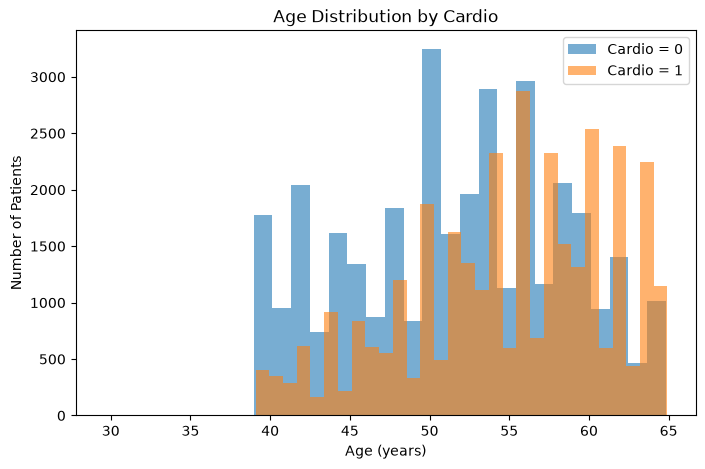

In [56]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    df_model[df_model["cardio"] == 0]["age_years"],
    bins=30,
    alpha=0.6,
    label="Cardio = 0"
)

plt.hist(
    df_model[df_model["cardio"] == 1]["age_years"],
    bins=30,
    alpha=0.6,
    label="Cardio = 1"
)

plt.xlabel("Age (years)")
plt.ylabel("Number of Patients")
plt.title("Age Distribution by Cardio")
plt.legend()
plt.show()

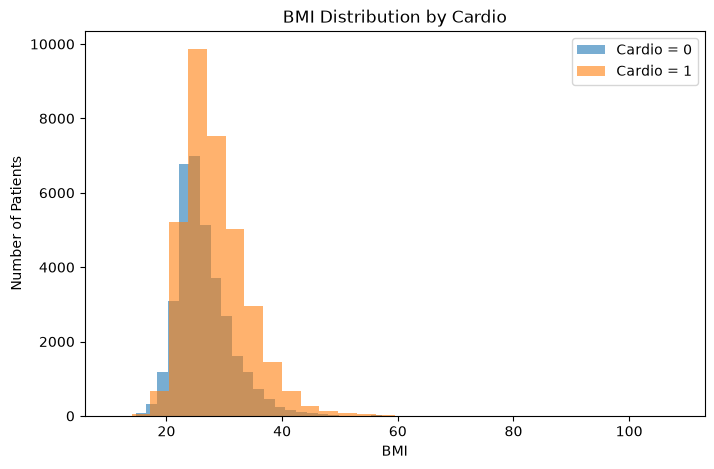

In [57]:
plt.figure(figsize=(8, 5))

plt.hist(
    df_model[df_model["cardio"] == 0]["BMI"],
    bins=30,
    alpha=0.6,
    label="Cardio = 0"
)

plt.hist(
    df_model[df_model["cardio"] == 1]["BMI"],
    bins=30,
    alpha=0.6,
    label="Cardio = 1"
)

plt.xlabel("BMI")
plt.ylabel("Number of Patients")
plt.title("BMI Distribution by Cardio")
plt.legend()
plt.show()

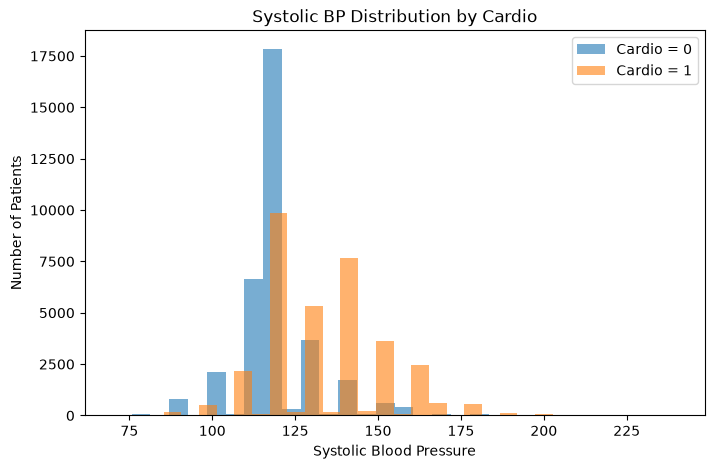

In [58]:
plt.figure(figsize=(8, 5))

plt.hist(
    df_model[df_model["cardio"] == 0]["ap_hi"],
    bins=30,
    alpha=0.6,
    label="Cardio = 0"
)

plt.hist(
    df_model[df_model["cardio"] == 1]["ap_hi"],
    bins=30,
    alpha=0.6,
    label="Cardio = 1"
)

plt.xlabel("Systolic Blood Pressure")
plt.ylabel("Number of Patients")
plt.title("Systolic BP Distribution by Cardio")
plt.legend()
plt.show()

In [59]:
correlation_with_target = (
    df_model
    .corr(numeric_only=True)["cardio"]
    .sort_values(ascending=False)
)

correlation_with_target

cardio         1.000000
ap_hi          0.428219
ap_lo          0.340861
age            0.239382
age_years      0.239382
cholesterol    0.221466
BMI            0.189600
weight         0.180131
gluc           0.089740
gender         0.007152
id             0.003847
alco          -0.008571
height_m      -0.011834
height        -0.011834
smoke         -0.016361
active        -0.037631
Name: cardio, dtype: float64

In [60]:
X = df_model.drop(columns=["cardio"])
y = df_model["cardio"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (68610, 15)
y shape: (68610,)


In [61]:
print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

Features:
['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'age_years', 'height_m', 'BMI']

Target:
cardio


In [62]:
X = X.drop(columns=["id"])

print("X shape after removing ID:", X.shape)
print(X.columns.tolist())

X shape after removing ID: (68610, 14)
['age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'age_years', 'height_m', 'BMI']


In [63]:
print("Missing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Missing values in X: 0
Missing values in y: 0

X shape: (68610, 14)
y shape: (68610,)


In [64]:
X = X.drop(columns=["age", "height"])

print("X shape after removing redundant features:", X.shape)
print("\nFinal features:")
print(X.columns.tolist())

X shape after removing redundant features: (68610, 12)

Final features:
['gender', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'age_years', 'height_m', 'BMI']


In [65]:
print("Final X shape:", X.shape)
print("Final y shape:", y.shape)

print("\nMissing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())

print("\nFinal features:")
print(X.columns.tolist())

Final X shape: (68610, 12)
Final y shape: (68610,)

Missing values in X: 0
Missing values in y: 0

Final features:
['gender', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'age_years', 'height_m', 'BMI']


In [66]:
print(X.dtypes)

gender           int64
weight         float64
ap_hi            int64
ap_lo            int64
cholesterol      int64
gluc             int64
smoke            int64
alco             int64
active           int64
age_years      float64
height_m       float64
BMI            float64
dtype: object


In [67]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (54888, 12)
X_test shape: (13722, 12)
y_train shape: (54888,)
y_test shape: (13722,)


In [68]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training target distribution:
cardio
0    50.530171
1    49.469829
Name: proportion, dtype: float64

Testing target distribution:
cardio
0    50.531992
1    49.468008
Name: proportion, dtype: float64


In [69]:
X_train.describe().T[["min", "max", "mean", "std"]]

,min,max,mean,std
gender,1.000000,2.000000,1.350259,0.477055
weight,30.000000,200.000000,74.149032,14.316822
ap_hi,70.000000,240.000000,126.624326,16.705331
ap_lo,40.000000,150.000000,81.268365,9.437943
cholesterol,1.000000,3.000000,1.366146,0.679770
gluc,1.000000,3.000000,1.228556,0.575107
smoke,0.000000,1.000000,0.087961,0.283241
alco,0.000000,1.000000,0.053345,0.224723
active,0.000000,1.000000,0.803892,0.397055
age_years,29.730322,64.922656,53.289638,6.759038


In [70]:
from sklearn.preprocessing import StandardScaler

In [71]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

X_train_scaled shape: (54888, 12)
X_test_scaled shape: (13722, 12)


In [72]:
import pandas as pd

X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns
)

X_train_scaled_df.describe().T[["mean", "std"]]

,mean,std
gender,2.112676e-16,1.000009
weight,4.630541e-16,1.000009
ap_hi,3.931494e-16,1.000009
ap_lo,3.334714e-16,1.000009
cholesterol,3.624690e-17,1.000009
gluc,-1.201326e-16,1.000009
smoke,7.663630e-17,1.000009
alco,3.844760e-17,1.000009
active,-1.144366e-16,1.000009
age_years,-7.896645e-18,1.000009


In [73]:
from sklearn.linear_model import LogisticRegression

In [74]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [75]:
y_pred = logistic_model.predict(X_test_scaled)

print("Predictions generated.")
print("Number of predictions:", len(y_pred))

Predictions generated.
Number of predictions: 13722


In [76]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression Accuracy:", accuracy)

Logistic Regression Accuracy: 0.7289024923480543


Confusion Matrix:
[[5425 1509]
 [2211 4577]]


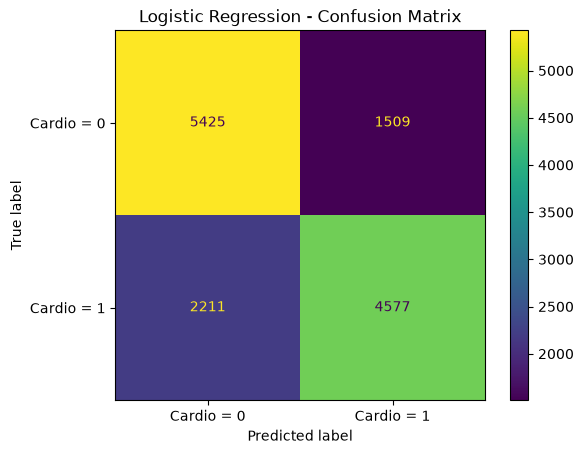

In [77]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Cardio = 0", "Cardio = 1"]
)

disp.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [78]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Precision: 0.7520538941833717
Recall: 0.6742781378903948
F1 Score: 0.711045518098493


In [79]:
y_prob = logistic_model.predict_proba(X_test_scaled)[:, 1]

In [80]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.7919080762994946


In [81]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = DecisionTreeClassifier(
    random_state=42
)

decision_tree.fit(X_train_scaled, y_train)

print("Decision Tree trained successfully.")

Decision Tree trained successfully.


In [82]:
y_pred_dt = decision_tree.predict(X_test_scaled)

print("Predictions generated.")
print("Number of predictions:", len(y_pred_dt))

Predictions generated.
Number of predictions: 13722


In [83]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)

y_prob_dt = decision_tree.predict_proba(X_test_scaled)[:, 1]
roc_auc_dt = roc_auc_score(y_test, y_prob_dt)

print("Decision Tree Results")
print("---------------------")
print("Accuracy :", accuracy_dt)
print("Precision:", precision_dt)
print("Recall   :", recall_dt)
print("F1 Score :", f1_dt)
print("ROC-AUC  :", roc_auc_dt)

Decision Tree Results
---------------------
Accuracy : 0.6366418889374726
Precision: 0.6316096990943617
Recall   : 0.6370064820271066
F1 Score : 0.6342966114126448
ROC-AUC  : 0.6366925956815834


Confusion Matrix:
[[4412 2522]
 [2464 4324]]


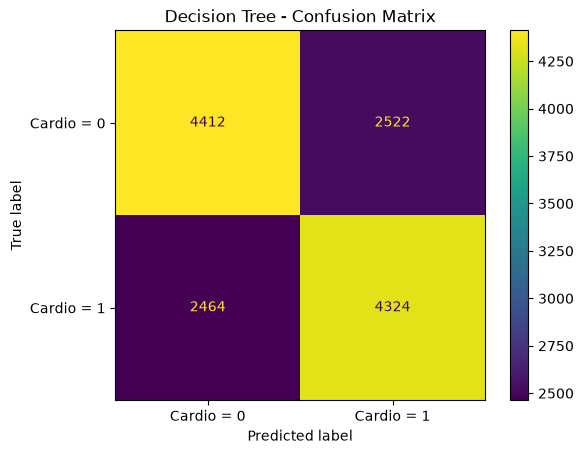

In [84]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_dt = confusion_matrix(y_test, y_pred_dt)

print("Confusion Matrix:")
print(cm_dt)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=["Cardio = 0", "Cardio = 1"]
)

disp.plot()
plt.title("Decision Tree - Confusion Matrix")
plt.show()

In [85]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [accuracy, accuracy_dt],
    "Precision": [precision, precision_dt],
    "Recall": [recall, recall_dt],
    "F1 Score": [f1, f1_dt],
    "ROC-AUC": [roc_auc, roc_auc_dt]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.728902,0.752054,0.674278,0.711046,0.791908
1,Decision Tree,0.636642,0.631610,0.637006,0.634297,0.636693


In [86]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train_scaled, y_train)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [87]:
y_pred_rf = random_forest.predict(X_test_scaled)

print("Predictions generated.")
print("Number of predictions:", len(y_pred_rf))

Predictions generated.
Number of predictions: 13722


In [88]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

y_prob_rf = random_forest.predict_proba(X_test_scaled)[:, 1]
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Random Forest Results")
print("---------------------")
print("Accuracy :", accuracy_rf)
print("Precision:", precision_rf)
print("Recall   :", recall_rf)
print("F1 Score :", f1_rf)
print("ROC-AUC  :", roc_auc_rf)

Random Forest Results
---------------------
Accuracy : 0.7130884710683574
Precision: 0.7124124571598868
Recall   : 0.7043311726576311
F1 Score : 0.7083487665753019
ROC-AUC  : 0.7725171704796754


Confusion Matrix:
[[5004 1930]
 [2007 4781]]


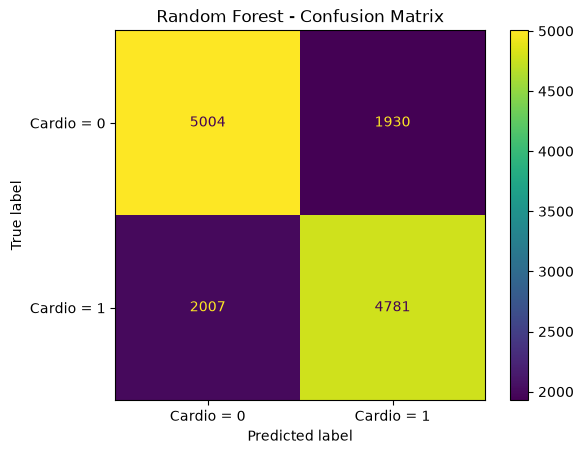

In [89]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_rf = confusion_matrix(y_test, y_pred_rf)

print("Confusion Matrix:")
print(cm_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Cardio = 0", "Cardio = 1"]
)

disp.plot()
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [90]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy,
        accuracy_dt,
        accuracy_rf
    ],
    "Precision": [
        precision,
        precision_dt,
        precision_rf
    ],
    "Recall": [
        recall,
        recall_dt,
        recall_rf
    ],
    "F1 Score": [
        f1,
        f1_dt,
        f1_rf
    ],
    "ROC-AUC": [
        roc_auc,
        roc_auc_dt,
        roc_auc_rf
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.728902,0.752054,0.674278,0.711046,0.791908
1,Decision Tree,0.636642,0.631610,0.637006,0.634297,0.636693
2,Random Forest,0.713088,0.712412,0.704331,0.708349,0.772517


In [91]:
from sklearn.model_selection import GridSearchCV

logistic_params = {
    "C": [0.01, 0.1, 1, 10, 100]
}

logistic_grid = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=42),
    logistic_params,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

logistic_grid.fit(X_train_scaled, y_train)

print("Best Logistic Regression Parameters:")
print(logistic_grid.best_params_)

print("Best CV ROC-AUC:")
print(logistic_grid.best_score_)

Best Logistic Regression Parameters:
{'C': 0.1}
Best CV ROC-AUC:
0.7910760643685482


In [92]:
best_logistic = logistic_grid.best_estimator_

y_pred_log_tuned = best_logistic.predict(X_test_scaled)
y_prob_log_tuned = best_logistic.predict_proba(X_test_scaled)[:, 1]

print("Test Accuracy:", accuracy_score(y_test, y_pred_log_tuned))
print("Test Precision:", precision_score(y_test, y_pred_log_tuned))
print("Test Recall:", recall_score(y_test, y_pred_log_tuned))
print("Test F1:", f1_score(y_test, y_pred_log_tuned))
print("Test ROC-AUC:", roc_auc_score(y_test, y_prob_log_tuned))

Test Accuracy: 0.7291211193703542
Test Precision: 0.7522589124363397
Test Recall: 0.674572775486152
Test F1: 0.7113009708737864
Test ROC-AUC: 0.7919277074747526


In [93]:
rf_params = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    rf_params,
    cv=3,
    scoring="roc_auc",
    n_jobs=-1
)

rf_grid.fit(X_train_scaled, y_train)

print("Best Random Forest Parameters:")
print(rf_grid.best_params_)

print("Best CV ROC-AUC:")
print(rf_grid.best_score_)

/Users/hiralrikhye/Desktop/LifePredict/ML-service/.venv/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best Random Forest Parameters:
{'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 200}
Best CV ROC-AUC:
0.8002916848592507


In [94]:
best_rf = rf_grid.best_estimator_

y_pred_rf_tuned = best_rf.predict(X_test_scaled)
y_prob_rf_tuned = best_rf.predict_proba(X_test_scaled)[:, 1]

print("Test Accuracy:", accuracy_score(y_test, y_pred_rf_tuned))
print("Test Precision:", precision_score(y_test, y_pred_rf_tuned))
print("Test Recall:", recall_score(y_test, y_pred_rf_tuned))
print("Test F1:", f1_score(y_test, y_pred_rf_tuned))
print("Test ROC-AUC:", roc_auc_score(y_test, y_prob_rf_tuned))

Test Accuracy: 0.7375746975659525
Test Precision: 0.7611866907064415
Test Recall: 0.6841484973482617
Test F1: 0.7206144774614012
Test ROC-AUC: 0.8007269993587149


In [95]:
final_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Tuned Logistic Regression",
        "Tuned Random Forest"
    ],
    "Accuracy": [
        accuracy,
        accuracy_dt,
        accuracy_rf,
        accuracy_score(y_test, y_pred_log_tuned),
        accuracy_score(y_test, y_pred_rf_tuned)
    ],
    "Precision": [
        precision,
        precision_dt,
        precision_rf,
        precision_score(y_test, y_pred_log_tuned),
        precision_score(y_test, y_pred_rf_tuned)
    ],
    "Recall": [
        recall,
        recall_dt,
        recall_rf,
        recall_score(y_test, y_pred_log_tuned),
        recall_score(y_test, y_pred_rf_tuned)
    ],
    "F1 Score": [
        f1,
        f1_dt,
        f1_rf,
        f1_score(y_test, y_pred_log_tuned),
        f1_score(y_test, y_pred_rf_tuned)
    ],
    "ROC-AUC": [
        roc_auc,
        roc_auc_dt,
        roc_auc_rf,
        roc_auc_score(y_test, y_prob_log_tuned),
        roc_auc_score(y_test, y_prob_rf_tuned)
    ]
})

final_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.728902,0.752054,0.674278,0.711046,0.791908
1,Decision Tree,0.636642,0.631610,0.637006,0.634297,0.636693
2,Random Forest,0.713088,0.712412,0.704331,0.708349,0.772517
3,Tuned Logistic Regression,0.729121,0.752259,0.674573,0.711301,0.791928
4,Tuned Random Forest,0.737575,0.761187,0.684148,0.720614,0.800727


In [96]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_rf.feature_importances_
}).sort_values("Importance", ascending=False)

feature_importance

,Feature,Importance
2,ap_hi,0.447550
3,ap_lo,0.181360
9,age_years,0.134530
4,cholesterol,0.086415
11,BMI,0.054773
1,weight,0.040324
10,height_m,0.023611
5,gluc,0.011725
8,active,0.008038
6,smoke,0.004279


In [97]:
import joblib

joblib.dump(best_rf, "../models/lifepredict_random_forest.pkl")

print("Model saved successfully.")

Model saved successfully.


In [98]:
joblib.dump(scaler, "../models/lifepredict_scaler.pkl")

print("Scaler saved successfully.")

Scaler saved successfully.


In [99]:
# Sample user input

sample_user = pd.DataFrame([{
    "gender": 1,
    "weight": 70,
    "ap_hi": 120,
    "ap_lo": 80,
    "cholesterol": 1,
    "gluc": 1,
    "smoke": 0,
    "alco": 0,
    "active": 1,
    "age_years": 25,
    "height_m": 1.65,
    "BMI": 25.71
}])

sample_user

,gender,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,age_years,height_m,BMI
0,1,70,120,80,1,1,0,0,1,25,1.65,25.71


In [100]:
X_sample_scaled = scaler.transform(sample_user)

print("Input scaled successfully.")
print(X_sample_scaled)

Input scaled successfully.
[[-0.73421666 -0.2898038  -0.39654325 -0.13439117 -0.53863663 -0.39741903
  -0.31055477 -0.23738374  0.49391181 -4.18549139  0.07325868 -0.33362933]]


In [101]:
prediction = best_rf.predict(X_sample_scaled)
probability = best_rf.predict_proba(X_sample_scaled)

print("Predicted Cardio:", prediction[0])
print("Probability of Cardio = 0:", probability[0][0])
print("Probability of Cardio = 1:", probability[0][1])

Predicted Cardio: 0
Probability of Cardio = 0: 0.8183608102709367
Probability of Cardio = 1: 0.18163918972906348
